In [1]:
print("Simulador Turístico de Mompox")
print("Notebook funcionando correctamente")

Simulador Turístico de Mompox
Notebook funcionando correctamente


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RUTA_DATOS = Path("../datos/RNT_Mompox_preparado.csv")
RUTA_SEGMENTOS = Path("../datos/RNT_Mompox_segmentado.csv")

df = pd.read_csv(RUTA_DATOS, encoding="utf-8-sig")
segmentos = pd.read_csv(RUTA_SEGMENTOS, encoding="utf-8-sig")

sns.set_theme(style="whitegrid")

print("Datos preparados:", df.shape)
print("Datos segmentados:", segmentos.shape)

display(df.head())
display(segmentos.head())

Datos preparados: (960, 15)
Datos segmentados: (299, 7)


,codigo_rnt,estado_rnt,razon_social_establecimiento,departamento,codigo_departamento,municipio,codigo_municipio,nit,categoria,sub_categoria,numero_de_habitaciones,numero_de_camas,numero_de_empleados,año,ofrece_alojamiento
0,7.903,ACTIVO,HOTEL SANTA CRUZ DE MOMPOX,BOLIVAR,13,MOMPOS,13468,33213478,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOTEL,24,55.0,1,2019,True
1,23.462,ACTIVO,HOTEL BIOMA,BOLIVAR,13,MOMPOS,13468,900372605,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOTEL,12,17.0,9,2019,True
2,28.276,ACTIVO,HOTEL ISLA CAPRI,BOLIVAR,13,MOMPOS,13468,23083717,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOTEL,12,21.0,3,2019,True
3,29.458,ACTIVO,CASA HOTEL LA CASONA,BOLIVAR,13,MOMPOS,13468,33211138,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOTEL,7,18.0,2,2019,True
4,29.860,ACTIVO,HOTEL VILLA DE MOMPOX,BOLIVAR,13,MOMPOS,13468,22991552,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOTEL,9,19.0,1,2019,True


,categoria,sub_categoria,numero_de_habitaciones,numero_de_camas,numero_de_empleados,año,segmento
0,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,3,6,3,2019,Alojamiento pequeño-mediano
1,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,7,14,1,2019,Alojamiento pequeño-mediano
2,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,4,13,1,2019,Alojamiento pequeño-mediano
3,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,3,5,1,2019,Microoferta y servicios
4,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,8,10,2,2019,Alojamiento pequeño-mediano


In [3]:
# 1. Información general
print("DIMENSIONES DEL CONJUNTO DE DATOS")
print(f"Registros: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

print("\nTIPOS DE DATOS")
display(df.dtypes.to_frame(name="Tipo de dato"))

# 2. Valores faltantes
print("\nVALORES FALTANTES POR COLUMNA")
faltantes = df.isnull().sum().sort_values(ascending=False)
display(faltantes.to_frame(name="Valores faltantes"))

# 3. Categorías turísticas
print("\nDISTRIBUCIÓN POR CATEGORÍA TURÍSTICA")
display(df["categoria"].value_counts().to_frame(name="Cantidad"))

# 4. Estadísticas descriptivas
columnas_numericas = [
    "numero_de_habitaciones",
    "numero_de_camas",
    "numero_de_empleados",
    "año"
]

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df[columnas_numericas].describe().round(2))

DIMENSIONES DEL CONJUNTO DE DATOS
Registros: 960
Columnas: 15

TIPOS DE DATOS


,Tipo de dato
codigo_rnt,float64
estado_rnt,str
razon_social_establecimiento,str
departamento,str
codigo_departamento,int64
municipio,str
codigo_municipio,int64
nit,int64
categoria,str
sub_categoria,str



VALORES FALTANTES POR COLUMNA


,Valores faltantes
codigo_rnt,0
estado_rnt,0
razon_social_establecimiento,0
departamento,0
codigo_departamento,0
municipio,0
codigo_municipio,0
nit,0
categoria,0
sub_categoria,0



DISTRIBUCIÓN POR CATEGORÍA TURÍSTICA


,Cantidad
categoria,
ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,500
VIVIENDAS TURÍSTICAS,226
AGENCIAS DE VIAJES,109
GUIAS DE TURISMO,101
EMPRESAS DE TRANSPORTE TERRESTRE AUTOMOTOR,8
OTROS TIPOS DE HOSPEDAJE TURÍSTICOS NO PERMANENTES,7
"OPERADORES PROFESIONALES DE CONGRESOS, FERIAS Y CONVENCIONES",6
ESTABLECIMIENTOS DE GASTRONOMÍA Y SIMILARES,2
OFICINAS DE REPRESENTACION TURÍSTICA,1



ESTADÍSTICAS DESCRIPTIVAS


,numero_de_habitaciones,numero_de_camas,numero_de_empleados,año
count,960.00,960.00,960.00,960.00
mean,4.97,10.45,1.24,2023.37
std,5.64,10.67,1.44,2.12
min,0.00,0.00,0.00,2019.00
25%,1.00,2.00,1.00,2022.00
50%,4.00,8.00,1.00,2024.00
75%,7.00,15.00,1.00,2025.00
max,55.00,55.00,13.00,2026.00


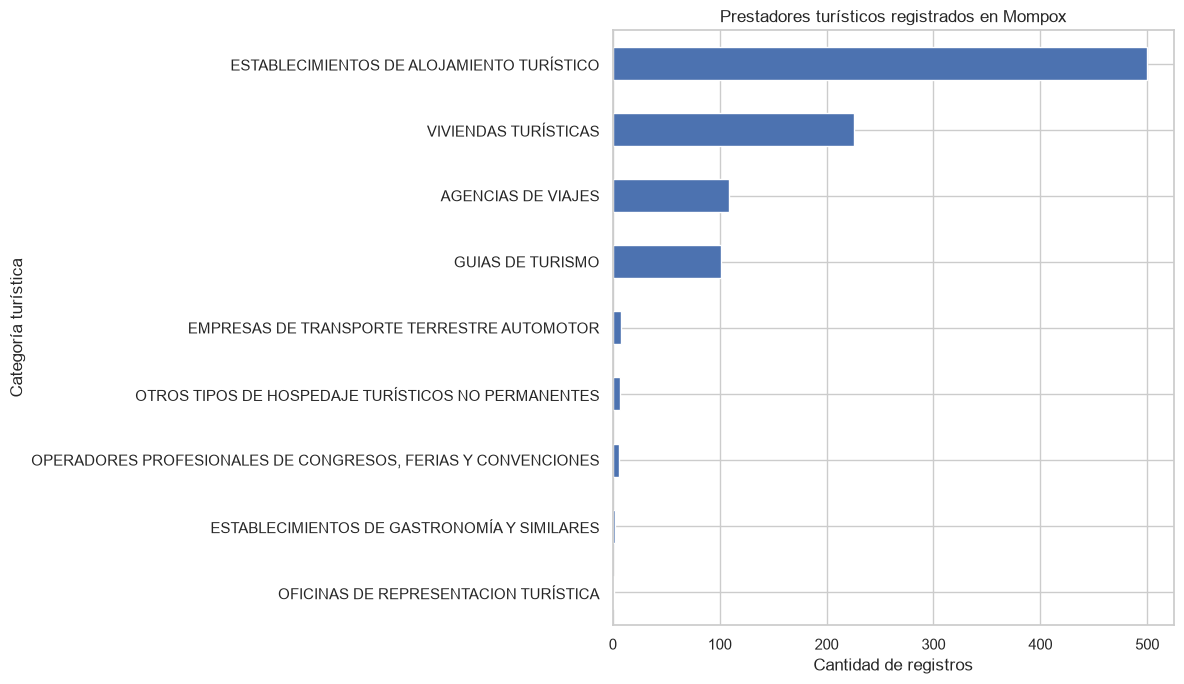

In [4]:
conteo = df["categoria"].value_counts().sort_values()

plt.figure(figsize=(12, 7))
conteo.plot(kind="barh")

plt.title("Prestadores turísticos registrados en Mompox")
plt.xlabel("Cantidad de registros")
plt.ylabel("Categoría turística")
plt.tight_layout()
plt.show()

COLUMNAS DEL ARCHIVO SEGMENTADO
['categoria', 'sub_categoria', 'numero_de_habitaciones', 'numero_de_camas', 'numero_de_empleados', 'año', 'segmento']

DISTRIBUCIÓN DE LOS SEGMENTOS


,Cantidad de registros
segmento,
Alojamiento grande,35
Alojamiento pequeño-mediano,96
Microoferta y servicios,168


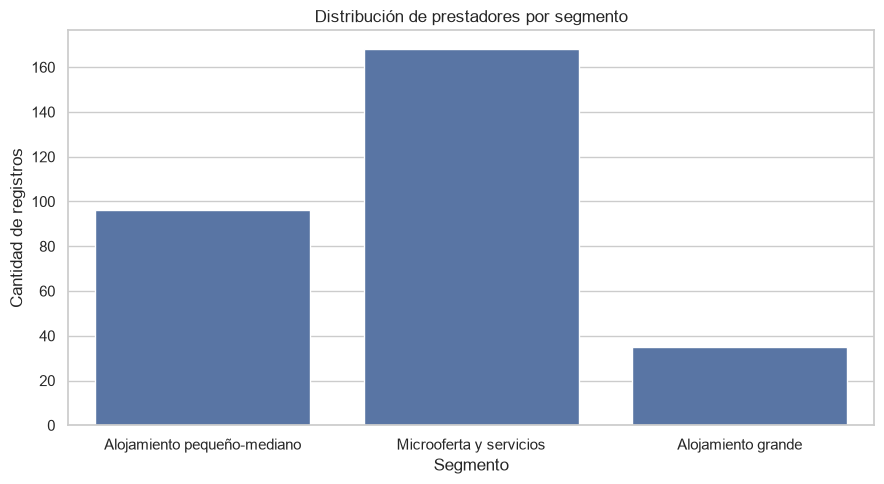

In [5]:
# Revisar las columnas disponibles
print("COLUMNAS DEL ARCHIVO SEGMENTADO")
print(segmentos.columns.tolist())

# Cantidad de registros por segmento
print("\nDISTRIBUCIÓN DE LOS SEGMENTOS")
display(
    segmentos["segmento"]
    .value_counts()
    .sort_index()
    .to_frame(name="Cantidad de registros")
)

# Gráfica de distribución
plt.figure(figsize=(9, 5))
sns.countplot(data=segmentos, x="segmento")

plt.title("Distribución de prestadores por segmento")
plt.xlabel("Segmento")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()


In [6]:
# Variables numéricas disponibles en el archivo segmentado
variables = [
    "numero_de_habitaciones",
    "numero_de_camas",
    "numero_de_empleados",
    "año"
]

variables_disponibles = [
    columna for columna in variables
    if columna in segmentos.columns
]

# Promedios por segmento
resumen_segmentos = (
    segmentos.groupby("segmento")[variables_disponibles]
    .mean()
    .round(2)
)

print("PROMEDIOS POR SEGMENTO")
display(resumen_segmentos)

# Cantidad de registros por categoría dentro de cada segmento
if "categoria" in segmentos.columns:
    print("CATEGORÍAS POR SEGMENTO")
    display(pd.crosstab(segmentos["segmento"], segmentos["categoria"]))

PROMEDIOS POR SEGMENTO


,numero_de_habitaciones,numero_de_camas,numero_de_empleados,año
segmento,,,,
Alojamiento grande,13.57,30.60,2.40,2025.00
Alojamiento pequeño-mediano,5.61,12.48,1.12,2024.02
Microoferta y servicios,1.15,3.25,0.59,2024.87


CATEGORÍAS POR SEGMENTO


categoria,AGENCIAS DE VIAJES,EMPRESAS DE TRANSPORTE TERRESTRE AUTOMOTOR,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,ESTABLECIMIENTOS DE GASTRONOMÍA Y SIMILARES,GUIAS DE TURISMO,OFICINAS DE REPRESENTACION TURÍSTICA,"OPERADORES PROFESIONALES DE CONGRESOS, FERIAS Y CONVENCIONES",OTROS TIPOS DE HOSPEDAJE TURÍSTICOS NO PERMANENTES,VIVIENDAS TURÍSTICAS
segmento,,,,,,,,,
Alojamiento grande,0,0,32,0,0,0,0,0,3
Alojamiento pequeño-mediano,0,0,76,0,0,0,0,0,20
Microoferta y servicios,35,2,19,2,29,1,1,1,78


In [7]:
# Tabla completa de categorías por segmento
tabla_categorias = pd.crosstab(
    segmentos["segmento"],
    segmentos["categoria"],
    margins=True,
    margins_name="TOTAL"
)

display(tabla_categorias)

# Porcentaje de cada categoría dentro de cada segmento
porcentajes = (
    pd.crosstab(
        segmentos["segmento"],
        segmentos["categoria"],
        normalize="index"
    ) * 100
).round(2)

print("PORCENTAJE DE CADA CATEGORÍA POR SEGMENTO")
display(porcentajes)

# Tamaño de cada segmento
print("TAMAÑO DE LOS SEGMENTOS")
display(
    segmentos["segmento"]
    .value_counts()
    .rename("Cantidad")
    .to_frame()
)

categoria,AGENCIAS DE VIAJES,EMPRESAS DE TRANSPORTE TERRESTRE AUTOMOTOR,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,ESTABLECIMIENTOS DE GASTRONOMÍA Y SIMILARES,GUIAS DE TURISMO,OFICINAS DE REPRESENTACION TURÍSTICA,"OPERADORES PROFESIONALES DE CONGRESOS, FERIAS Y CONVENCIONES",OTROS TIPOS DE HOSPEDAJE TURÍSTICOS NO PERMANENTES,VIVIENDAS TURÍSTICAS,TOTAL
segmento,,,,,,,,,,
Alojamiento grande,0,0,32,0,0,0,0,0,3,35
Alojamiento pequeño-mediano,0,0,76,0,0,0,0,0,20,96
Microoferta y servicios,35,2,19,2,29,1,1,1,78,168
TOTAL,35,2,127,2,29,1,1,1,101,299


PORCENTAJE DE CADA CATEGORÍA POR SEGMENTO


categoria,AGENCIAS DE VIAJES,EMPRESAS DE TRANSPORTE TERRESTRE AUTOMOTOR,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,ESTABLECIMIENTOS DE GASTRONOMÍA Y SIMILARES,GUIAS DE TURISMO,OFICINAS DE REPRESENTACION TURÍSTICA,"OPERADORES PROFESIONALES DE CONGRESOS, FERIAS Y CONVENCIONES",OTROS TIPOS DE HOSPEDAJE TURÍSTICOS NO PERMANENTES,VIVIENDAS TURÍSTICAS
segmento,,,,,,,,,
Alojamiento grande,0.00,0.00,91.43,0.00,0.00,0.0,0.0,0.0,8.57
Alojamiento pequeño-mediano,0.00,0.00,79.17,0.00,0.00,0.0,0.0,0.0,20.83
Microoferta y servicios,20.83,1.19,11.31,1.19,17.26,0.6,0.6,0.6,46.43


TAMAÑO DE LOS SEGMENTOS


,Cantidad
segmento,
Microoferta y servicios,168
Alojamiento pequeño-mediano,96
Alojamiento grande,35


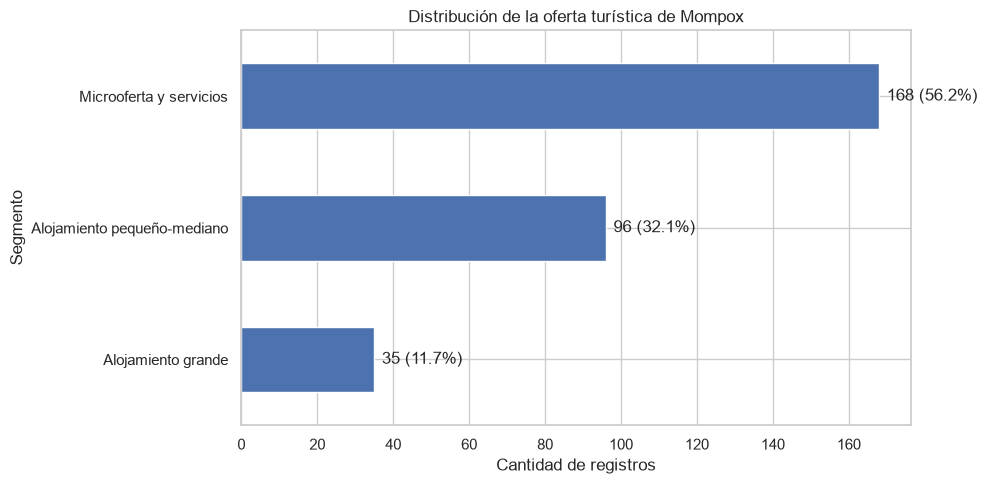

In [8]:
# Distribución de los segmentos
orden = (
    segmentos["segmento"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 5))

ax = orden.plot(kind="barh")

plt.title("Distribución de la oferta turística de Mompox")
plt.xlabel("Cantidad de registros")
plt.ylabel("Segmento")

total = orden.sum()

for i, cantidad in enumerate(orden):
    porcentaje = cantidad / total * 100
    ax.text(
        cantidad + 2,
        i,
        f"{cantidad} ({porcentaje:.1f}%)",
        va="center"
    )

plt.tight_layout()
plt.show()

In [9]:
from scipy import stats
import numpy as np
import pandas as pd

# Seleccionar prestadores dedicados al alojamiento
categorias_alojamiento = [
    "ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO",
    "VIVIENDAS TURÍSTICAS",
    "OTROS TIPOS DE HOSPEDAJE TURÍSTICOS NO PERMANENTES"
]

alojamiento = segmentos[
    segmentos["categoria"].isin(categorias_alojamiento)
].copy()

# Eliminar valores ausentes en la variable analizada
habitaciones = alojamiento["numero_de_habitaciones"].dropna()

n = len(habitaciones)
media = habitaciones.mean()
desviacion = habitaciones.std(ddof=1)
error_estandar = desviacion / np.sqrt(n)

# Intervalo de confianza del 95 % con distribución t
t_critico = stats.t.ppf(0.975, df=n - 1)
margen_error = t_critico * error_estandar

limite_inferior = media - margen_error
limite_superior = media + margen_error

print("INTERVALO DE CONFIANZA DEL 95 %")
print(f"Registros analizados: {n}")
print(f"Media de habitaciones: {media:.2f}")
print(f"Desviación estándar: {desviacion:.2f}")
print(f"Intervalo: [{limite_inferior:.2f}, {limite_superior:.2f}]")

INTERVALO DE CONFIANZA DEL 95 %
Registros analizados: 229
Media de habitaciones: 5.27
Desviación estándar: 4.60
Intervalo: [4.67, 5.87]


In [10]:
# Resumen de habitaciones por segmento
resumen = (
    segmentos.groupby("segmento")["numero_de_habitaciones"]
    .agg(["count", "mean", "std", "median"])
    .round(2)
)

resumen.columns = [
    "Cantidad de registros",
    "Media de habitaciones",
    "Desviación estándar",
    "Mediana de habitaciones"
]

display(resumen)

,Cantidad de registros,Media de habitaciones,Desviación estándar,Mediana de habitaciones
segmento,,,,
Alojamiento grande,35,13.57,4.36,13.0
Alojamiento pequeño-mediano,96,5.61,2.45,5.0
Microoferta y servicios,168,1.15,1.29,1.0


In [11]:
resumen = (
    segmentos.groupby("segmento")["numero_de_habitaciones"]
    .agg(["count", "mean", "std", "median"])
    .round(2)
)

resumen.columns = [
    "Cantidad de registros",
    "Media de habitaciones",
    "Desviación estándar",
    "Mediana de habitaciones"
]

display(resumen)

,Cantidad de registros,Media de habitaciones,Desviación estándar,Mediana de habitaciones
segmento,,,,
Alojamiento grande,35,13.57,4.36,13.0
Alojamiento pequeño-mediano,96,5.61,2.45,5.0
Microoferta y servicios,168,1.15,1.29,1.0


In [12]:
from scipy.stats import chi2_contingency

# Categorías relacionadas con alojamiento
categorias_alojamiento = [
    "ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO",
    "VIVIENDAS TURÍSTICAS",
    "OTROS TIPOS DE HOSPEDAJE TURÍSTICOS NO PERMANENTES"
]

# Crear una clasificación general
segmentos["tipo_prestador"] = np.where(
    segmentos["categoria"].isin(categorias_alojamiento),
    "Alojamiento",
    "Otros servicios"
)

# Tabla de contingencia
tabla = pd.crosstab(
    segmentos["segmento"],
    segmentos["tipo_prestador"]
)

print("TABLA DE CONTINGENCIA")
display(tabla)

# Prueba chi-cuadrado
chi2, p_valor, grados_libertad, esperados = chi2_contingency(tabla)

print(f"Chi-cuadrado: {chi2:.4f}")
print(f"Grados de libertad: {grados_libertad}")
print(f"Valor p: {p_valor:.6f}")

print("\nFRECUENCIAS ESPERADAS")
display(
    pd.DataFrame(
        esperados,
        index=tabla.index,
        columns=tabla.columns
    ).round(2)
)

# Decisión estadística
alpha = 0.05

if p_valor < alpha:
    print("\nSe rechaza H0: existe evidencia de asociación entre las variables.")
else:
    print("\nNo se rechaza H0: no hay evidencia suficiente de asociación.")

TABLA DE CONTINGENCIA


tipo_prestador,Alojamiento,Otros servicios
segmento,,
Alojamiento grande,35,0
Alojamiento pequeño-mediano,96,0
Microoferta y servicios,98,70


Chi-cuadrado: 71.2682
Grados de libertad: 2
Valor p: 0.000000

FRECUENCIAS ESPERADAS


tipo_prestador,Alojamiento,Otros servicios
segmento,,
Alojamiento grande,26.81,8.19
Alojamiento pequeño-mediano,73.53,22.47
Microoferta y servicios,128.67,39.33



Se rechaza H0: existe evidencia de asociación entre las variables.


In [13]:

import pandas as pd
from pathlib import Path

ruta = Path("../datos/RNT_Mompox_segmentado.csv")
segmentos = pd.read_csv(ruta)

print("Dimensiones del archivo:", segmentos.shape)
print("\nColumnas disponibles:")
print(segmentos.columns.tolist())

print("\nPrimeros registros:")
display(segmentos.head())

print("\nCantidad de registros por segmento:")
print(segmentos["segmento"].value_counts(dropna=False))


Dimensiones del archivo: (299, 7)

Columnas disponibles:
['categoria', 'sub_categoria', 'numero_de_habitaciones', 'numero_de_camas', 'numero_de_empleados', 'año', 'segmento']

Primeros registros:


,categoria,sub_categoria,numero_de_habitaciones,numero_de_camas,numero_de_empleados,año,segmento
0,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,3,6,3,2019,Alojamiento pequeño-mediano
1,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,7,14,1,2019,Alojamiento pequeño-mediano
2,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,4,13,1,2019,Alojamiento pequeño-mediano
3,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,3,5,1,2019,Microoferta y servicios
4,ESTABLECIMIENTOS DE ALOJAMIENTO TURÍSTICO,HOSTAL,8,10,2,2019,Alojamiento pequeño-mediano



Cantidad de registros por segmento:
segmento
Microoferta y servicios        168
Alojamiento pequeño-mediano     96
Alojamiento grande              35
Name: count, dtype: int64


In [14]:

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np

variables = [
    "numero_de_habitaciones",
    "numero_de_camas",
    "numero_de_empleados"
]

# Seleccionar variables numéricas y conservar las filas completas
datos_cluster = segmentos[variables + ["segmento"]].copy()

for columna in variables:
    datos_cluster[columna] = pd.to_numeric(
        datos_cluster[columna], errors="coerce"
    )

datos_cluster = datos_cluster.dropna(
    subset=variables + ["segmento"]
)

# Escalar las variables para que tengan una importancia comparable
escalador = StandardScaler()
X_escalado = escalador.fit_transform(datos_cluster[variables])

etiquetas = datos_cluster["segmento"].astype(str)

print("Registros utilizados:", len(datos_cluster))
print("Cantidad de segmentos:", etiquetas.nunique())
print("\nRegistros por segmento:")
print(etiquetas.value_counts())


Registros utilizados: 299
Cantidad de segmentos: 3

Registros por segmento:
segmento
Microoferta y servicios        168
Alojamiento pequeño-mediano     96
Alojamiento grande              35
Name: count, dtype: int64


In [15]:

from sklearn.metrics import silhouette_score

silueta = silhouette_score(X_escalado, etiquetas)

print(f"Coeficiente de silueta: {silueta:.4f}")


Coeficiente de silueta: 0.4023


In [16]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Crear una nueva segmentación de referencia
modelo_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

etiquetas_kmeans = modelo_kmeans.fit_predict(X_escalado)

# Evaluar la nueva segmentación
silueta_kmeans = silhouette_score(
    X_escalado,
    etiquetas_kmeans
)

print("VALIDACIÓN DE LA SEGMENTACIÓN")
print(f"Silueta actual:  {silueta:.4f}")
print(f"Silueta K-Means: {silueta_kmeans:.4f}")

if silueta_kmeans > silueta:
    print("\nK-Means obtuvo una silueta superior.")
elif silueta_kmeans < silueta:
    print("\nLa segmentación actual obtuvo una silueta superior.")
else:
    print("\nAmbas segmentaciones obtuvieron el mismo resultado.")


VALIDACIÓN DE LA SEGMENTACIÓN
Silueta actual:  0.4023
Silueta K-Means: 0.4023

Ambas segmentaciones obtuvieron el mismo resultado.


In [17]:

# Comparar los segmentos actuales con los nuevos grupos de K-Means
comparacion = pd.crosstab(
    etiquetas,
    etiquetas_kmeans,
    rownames=["Segmento actual"],
    colnames=["Grupo K-Means"]
)

display(comparacion)

# Comparar las asignaciones registro por registro
coincidencias = (
    (etiquetas.reset_index(drop=True) ==
     pd.Series(etiquetas_kmeans)).mean()
)

print(f"Coincidencia directa: {coincidencias:.2%}")


Grupo K-Means,0,1,2
Segmento actual,,,
Alojamiento grande,0,0,35
Alojamiento pequeño-mediano,96,0,0
Microoferta y servicios,0,168,0


Coincidencia directa: 0.00%


In [18]:

from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(etiquetas, etiquetas_kmeans)

print(f"Índice Rand ajustado (ARI): {ari:.4f}")

if ari == 1.0:
    print("Confirmado: ambas segmentaciones generan los mismos grupos.")
else:
    print("Las segmentaciones presentan algunas diferencias.")


Índice Rand ajustado (ARI): 1.0000
Confirmado: ambas segmentaciones generan los mismos grupos.
